# Load Dataset

In [ ]:
from pathlib import Path
import os
import cv2
import numpy as np
from matplotlib import pyplot as plt

import tensorflow as tf
from sklearn.model_selection import train_test_split

In [ ]:
train_dir = "dataset/seg_train/seg_train"
test_dir = "dataset/seg_test/seg_test"

In [ ]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)


val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


# Data Exploration

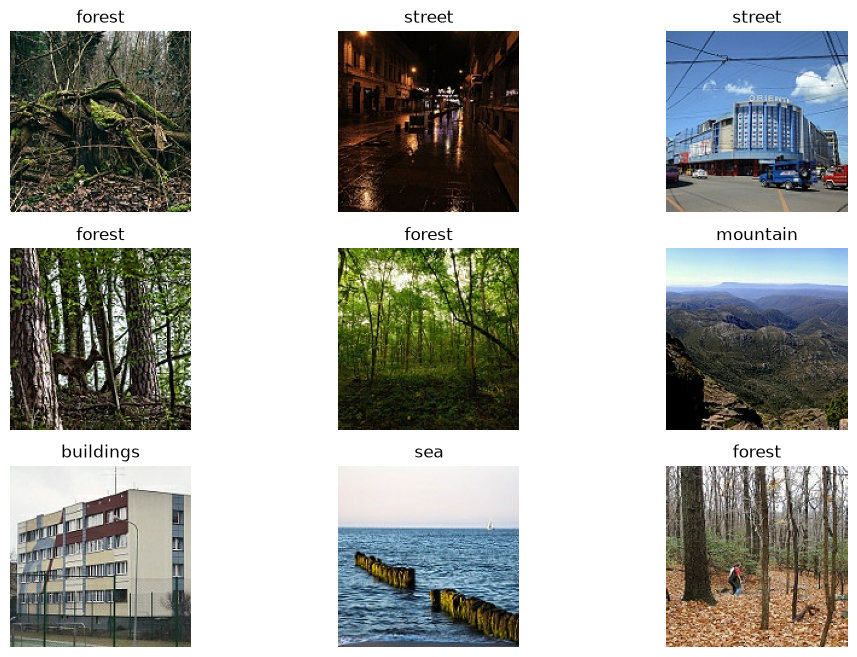

In [6]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.show()

In [7]:
print(train_ds.element_spec)

(TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [8]:
images, labels = next(iter(train_ds))

image = images[7]
print(image.shape)

label = labels[7]
print(label.numpy())

(150, 150, 3)
0


# Preprocess Data (for model from scratch)

In [9]:
AUTOTUNE = tf.data.AUTOTUNE

def normalize_images(images, labels):
    images = images / 255.0
    return images, labels

val_preprocessed = val_ds.map(normalize_images)
test_preprocessed = test_ds.map(normalize_images)

In [10]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

train_preprocessed = train_ds.map(
    lambda images, labels: (data_augmentation(images, training=True) / 255.0, labels)
)

In [11]:
train_preprocessed = train_preprocessed.prefetch(AUTOTUNE)
val_preprocessed = val_preprocessed.prefetch(AUTOTUNE)
test_preprocessed = test_preprocessed.prefetch(AUTOTUNE)

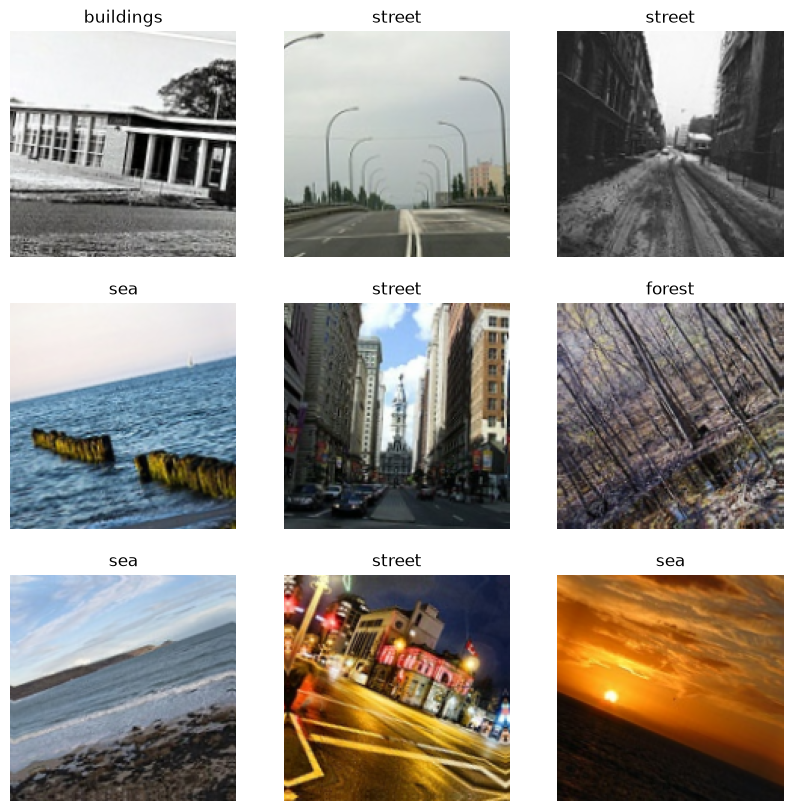

In [12]:
plt.figure(figsize=(10, 10))

for images, labels in train_preprocessed.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.show()

# Pretrained Model

In [ ]:
from keras.applications.vgg16 import VGG16, preprocess_input
from keras.layers import Dense, Flatten, Dropout
from keras import models,layers

In [ ]:
def vgg_preprocessing(images, labels):
    images = preprocess_input(images)
    return images, labels


train_vgg = train_ds.map(vgg_preprocessing)
val_vgg = val_ds.map(vgg_preprocessing)
test_vgg = test_ds.map(vgg_preprocessing)

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_vgg = train_vgg.prefetch(AUTOTUNE)
val_vgg = val_vgg.prefetch(AUTOTUNE)
test_vgg = test_vgg.prefetch(AUTOTUNE)

In [ ]:
vgg_base = VGG16(weights='imagenet', include_top=False, input_shape=(150, 150, 3))

In [ ]:
vgg_base.summary()

In [ ]:
for layer in vgg_base.layers:
    layer.trainable = False

In [ ]:
x = vgg_base.output
x = Flatten()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)

output = Dense(6, activation="softmax")(x)

In [ ]:
model = models.Model(
    inputs=vgg_base.input,
    outputs=output
)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_1 = model.fit(
    train_vgg,
    epochs=5,
    validation_data=val_vgg,
    verbose=1
)

### Fine-Tuning

In [ ]:
for layer in vgg_base.layers[:-4]:
    layer.trainable = False
for layer in vgg_base.layers[-4:]:
    layer.trainable = True

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_2 = model.fit(
    train_vgg,
    epochs=5,
    validation_data=val_vgg,
    verbose=1
)

In [ ]:
test_loss, test_acc = model.evaluate(test_vgg)
print(f"\n Test accuracy after fine-tuning: {test_acc:.4f}")

In [ ]:
#  keep the VGG model under its own name so it is NOT overwritten by the CNN section
vgg_model = model
vgg_model.save("vgg_finetuned.keras")

## Model From Scatch

In [14]:
import time, random
import seaborn as sns
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, accuracy_score
import pandas as pd

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

NUM_CLASSES = len(class_names)
INPUT_SHAPE = IMG_SIZE + (3,)

In [16]:
L2 = regularizers.l2(1e-4)

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False, kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation('relu')(x)

def build_cnn():
    inputs = keras.Input(shape=INPUT_SHAPE)
    x = inputs

    for filters, drop in ((32, 0.1), (64, 0.2), (128, 0.3), (256, 0.4)):
        x = conv_block(x, filters)
        if filters > 32:
            x = conv_block(x, filters) # 2 convs per block -> more seperation between similar scenes -> less underfitting & higher f1
        x = layers.MaxPooling2D()(x) # shrinking keeping strongest features
        x = layers.Dropout(drop)(x)

    x = layers.GlobalAveragePooling2D()(x) # instead of flatten -> fewer parameters -> less memorizing -> less overfitting

    x = layers.Dense(128, activation='relu', kernel_regularizer=L2)(x) # L2 weight penalty -> less overfitting
    x = layers.Dropout(0.5)(x) # dropout in dense head -> less overfitting

    output = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return keras.Model(inputs, output, name="cnn_from_scratch")

cnn_model = build_cnn()
cnn_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), 
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
cnn_model.summary()
    

Model: "cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 150, 150, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 75, 75, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 75, 75, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 37, 37, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 37, 37, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,199,462 (4.58 MB)

 Trainable params: 1,197,606 (4.57 MB)

 Non-trainable params: 1,856 (7.25 KB)

In [ ]:
callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint('best_cnn.keras', monitor='val_loss', save_best_only=True)
]

t0 = time.time()
history = cnn_model.fit(train_preprocessed, validation_data=val_preprocessed, epochs=10,
                    callbacks=callbacks, verbose=1)
print(f"training time: {(time.time() - t0)/60:.1f} min")

Epoch 1/10


c:\Users\Amira\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


104/351 ━━━━━━━━━━━━━━━━━━━━ 18:26 4s/step - accuracy: 0.4384 - loss: 1.4886

In [ ]:
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()
# Overfitting  = train curve keeps improving, validation stalls or gets worse
# Underfitting = both curves stay low
# Good fit     = both converge close together at high accuracy

In [ ]:
y_test = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = cnn_model.predict(test_preprocessed, verbose=0).argmax(axis=1)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
summary = pd.DataFrame({
    "Precision": [precision_score(y_test, y_pred, average=a) for a in ("macro", "weighted")],
    "Recall":    [recall_score(y_test, y_pred, average=a)    for a in ("macro", "weighted")],
    "F1":        [f1_score(y_test, y_pred, average=a)        for a in ("macro", "weighted")],
}, index=["Macro avg", "Weighted avg"])
display(summary.round(4))

per_class = pd.DataFrame({
    "Precision": precision_score(y_test, y_pred, average=None),
    "Recall":    recall_score(y_test, y_pred, average=None),
    "F1":        f1_score(y_test, y_pred, average=None),
    "Support":   np.bincount(y_test),
}, index=class_names)
display(per_class.round(4))

per_class[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 4), ylim=(0, 1.05))
plt.title("Per-class precision, recall and F1"); plt.xticks(rotation=0); plt.legend(loc="lower right")
plt.show()

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)")

cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[1])
ax[1].set_title("Confusion matrix (normalized by true class = recall)")
for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.show()

errors = [(class_names[i], class_names[j], cm[i, j]) for i in range(NUM_CLASSES)
        for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
top_errors = pd.DataFrame(errors, columns=["True class", "Predicted as", "Count"]).sort_values("Count", ascending=False)
print("Top 5 confusions:")
display(top_errors.head(5))

cnn_model.save("cnn_from_scratch_final.keras")

# Model Evaluation & Comparison
Evaluate both models (VGG16 pretrained vs CNN from scratch) on the **same test set** (`shuffle=False`):
- Accuracy, Precision, Recall, F1 (micro / macro / weighted)
- Confusion matrix for each model

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

# Load saved models if they are not already in memory (e.g. running this section alone)
if "vgg_model" not in globals():
    vgg_model = tf.keras.models.load_model("vgg_finetuned.keras")
if "cnn_model" not in globals():
    cnn_model = tf.keras.models.load_model("best_cnn.keras")

# Same test images, same order for both models (test_ds has shuffle=False)
y_true = np.concatenate([y.numpy() for _, y in test_ds])

# CNN uses test_preprocessed (/255), VGG uses test_vgg (preprocess_input)
y_pred_cnn = np.argmax(cnn_model.predict(test_preprocessed, verbose=0), axis=1)
y_pred_vgg = np.argmax(vgg_model.predict(test_vgg, verbose=0), axis=1)

print("Test images:", len(y_true))
print("Classes:", class_names)

NameError: name 'tf' is not defined

In [ ]:
def compute_metrics(y_true, y_pred, name):
    r = {"Model": name, "Accuracy": accuracy_score(y_true, y_pred)}
    for avg in ["micro", "macro", "weighted"]:
        r[f"Precision ({avg})"] = precision_score(y_true, y_pred, average=avg, zero_division=0)
        r[f"Recall ({avg})"]    = recall_score(y_true, y_pred, average=avg, zero_division=0)
        r[f"F1 ({avg})"]        = f1_score(y_true, y_pred, average=avg, zero_division=0)
    return r

metrics_df = pd.DataFrame([
    compute_metrics(y_true, y_pred_vgg, "VGG16 (Pretrained)"),
    compute_metrics(y_true, y_pred_cnn, "CNN (From Scratch)"),
]).set_index("Model").T.round(4)

display(metrics_df)
metrics_df.to_csv("metrics_comparison.csv")
# note: micro F1 = accuracy in single-label multi-class classification

In [ ]:
print("VGG16 (Pretrained):\n", classification_report(y_true, y_pred_vgg, target_names=class_names, digits=4))
print("CNN (From Scratch):\n", classification_report(y_true, y_pred_cnn, target_names=class_names, digits=4))

In [ ]:
def plot_cm(y_true, y_pred, title, filename):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax[0])
    ax[0].set_title(f"{title} (counts)")
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax[1])
    ax[1].set_title(f"{title} (normalized)")
    for a in ax:
        a.set_xlabel("Predicted"); a.set_ylabel("Actual")
    plt.tight_layout()
    plt.savefig(filename, dpi=200)
    plt.show()
    return cm

cm_vgg = plot_cm(y_true, y_pred_vgg, "Confusion Matrix - VGG16", "confusion_matrix_vgg16.png")
cm_cnn = plot_cm(y_true, y_pred_cnn, "Confusion Matrix - CNN From Scratch", "confusion_matrix_cnn.png")

In [ ]:
# Model comparison chart
metrics_df.loc[["Accuracy", "F1 (macro)", "F1 (weighted)", "F1 (micro)"]].plot(
    kind="bar", figsize=(9, 5), rot=0)
plt.title("Model Comparison"); plt.ylim(0, 1); plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=200)
plt.show()

# Most confused class pairs for each model (for the presentation summary)
def top_confusions(cm, n=5):
    rows = [(class_names[i], class_names[j], cm[i, j])
            for i in range(len(class_names)) for j in range(len(class_names))
            if i != j and cm[i, j] > 0]
    return pd.DataFrame(rows, columns=["True class", "Predicted as", "Count"]) \
             .sort_values("Count", ascending=False).head(n)

print("VGG16 - top confusions:");  display(top_confusions(cm_vgg))
print("CNN - top confusions:");    display(top_confusions(cm_cnn))